# Dual DWT watermark + ML-DSA-44 signature: technical walkthrough and demo

This notebook runs the whole pipeline from scratch: decomposing an image with the DWT, building the per-block
fingerprint, embedding it, simulating compression and manipulation, then verifying.
All the code is in the `wm/` folder and can be re-run (`Run All`).

**The problem.** When a photo is sent through a channel like WhatsApp, it is recompressed and its metadata is
stripped. A plain hash fails because it changes completely. We need a mark that
(1) survives reasonable compression, (2) stays sensitive to local edits, and (3) can prove the publisher.

**Warning.** This is a demo implementation for research and teaching, not a security product.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, cv2, hashlib, base64
import matplotlib.pyplot as plt
from wm import embed, imaging as im, robust_id, signing, verify, fingerprint as fp
from wm.config import *
from wm.dwt import decompose
plt.rcParams["figure.dpi"] = 110

bgr = im.sample_image(512)          # synthetic image; swap in your own in section 7
Y = im.luminance(bgr)
print("image size:", bgr.shape, "| block:", BLOCK_SIZE, "x", BLOCK_SIZE,
      "| number of blocks:", (Y.shape[0] // BLOCK_SIZE) * (Y.shape[1] // BLOCK_SIZE))

image size: (512, 512, 3) | block: 32 x 32 | number of blocks: 256


## 1. DWT: splitting one block into coarse and fine

The image is cut into 32x32-pixel blocks. Each block is decomposed with a **one-level Haar DWT** into
four 16x16 sub-bands:

- **LL**: the coarse shape (local average). Usually the most stable under compression.
- **LH, HL, HH**: fine detail (horizontal, vertical, diagonal edges).

32 is chosen so that LL and HL hold exactly 256 coefficients, the same as the fingerprint length (256 bits).

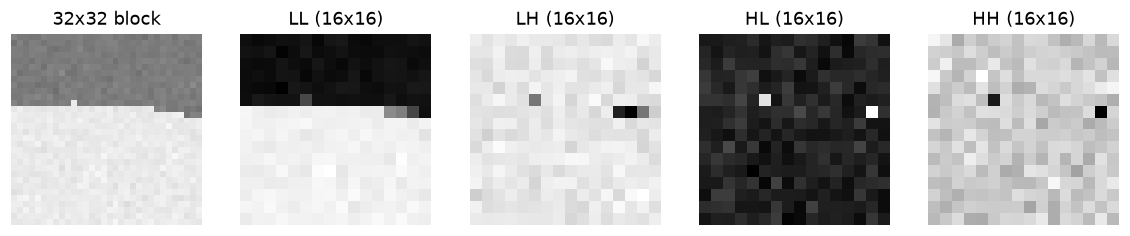

LL: (16, 16) | HL: (16, 16) -> 256 coefficients = 256 fingerprint bits


In [2]:
block = Y[160:192, 160:192].copy()
LL, LH, HL, HH = decompose(block, WAVELET)
fig, ax = plt.subplots(1, 5, figsize=(13, 2.8))
ax[0].imshow(block, cmap="gray", vmin=0, vmax=255); ax[0].set_title("32x32 block")
for a, (n, d) in zip(ax[1:], [("LL", LL), ("LH", LH), ("HL", HL), ("HH", HH)]):
    a.imshow(d, cmap="gray"); a.set_title(f"{n} (16x16)")
for a in ax: a.axis("off")
plt.show()
print("LL:", LL.shape, "| HL:", HL.shape, "-> 256 coefficients = 256 fingerprint bits")

## 2. Fingerprint, BER, and why not a plain hash

A block's **fingerprint** = the parity of the quantised LL (step `Q_LL_HASH`), XORed with a *position salt*
(deterministic pseudo-random bits derived from the block coordinates). The position salt means a block copied
from elsewhere no longer matches its new position (anti-splicing).

**BER (Bit Error Rate)** = the fraction of bits that differ between two bit sequences.

Compare with SHA-256 directly: change a single pixel and SHA-256 changes completely (avalanche effect), while the
fingerprint only shifts a little.

In [3]:
def block_fp(b):
    L, *_ = decompose(b, WAVELET)
    return fp.fingerprint_from_ll(L, Q_LL_HASH, 3, 4)

original = block.copy()
one_pixel = block.copy(); one_pixel[10, 10] = np.uint8((int(one_pixel[10, 10]) + 1) % 256)

h1 = hashlib.sha256(original.tobytes()).hexdigest()
h2 = hashlib.sha256(one_pixel.tobytes()).hexdigest()
print("SHA-256 original        :", h1[:32], "...")
print("SHA-256 1 pixel changed :", h2[:32], "...  <- completely different, nothing 'similar'")
b1 = np.unpackbits(np.frombuffer(bytes.fromhex(h1), np.uint8))
b2 = np.unpackbits(np.frombuffer(bytes.fromhex(h2), np.uint8))
print(f"fraction of SHA-256 bits that differ: {np.mean(b1 != b2):.2f}  (about 0.5 = random)\n")

print(f"fingerprint BER, 1 pixel changed : {fp.ber(block_fp(original), block_fp(one_pixel)):.3f}")
print(f"valid/invalid threshold          : {BER_THRESHOLD}")

SHA-256 original        : 36f0dcd165a83368362abfcc24059775 ...
SHA-256 1 pixel changed : 2a76476fafd2f92c37c13993dd010477 ...  <- completely different, nothing 'similar'
fraction of SHA-256 bits that differ: 0.48  (about 0.5 = random)

fingerprint BER, 1 pixel changed : 0.000
valid/invalid threshold          : 0.3


A small change gives a small BER, and BER grows with the size of the change (measured in section 5). That lets
us pick a **threshold (0.30)** that separates "reasonably compressed" from "edited". That is the core of
semi-fragile watermarking. The consequence is that a very small change inside one block can stay below the threshold.

## 3. Embedding the watermark

Per block: (a) plant the **robust ID** in LL (QIM, section 4), (b) compute the fingerprint from that LL,
(c) embed the 256 fingerprint bits into the 256 HL coefficients with parity QIM (step `Q_EMBED`), (d) inverse DWT.
For colour images only the luminance (Y) channel is touched, so the original colours are preserved.

PSNR (Y): 31.97 dB   | SHA-256 certificates per block: 256


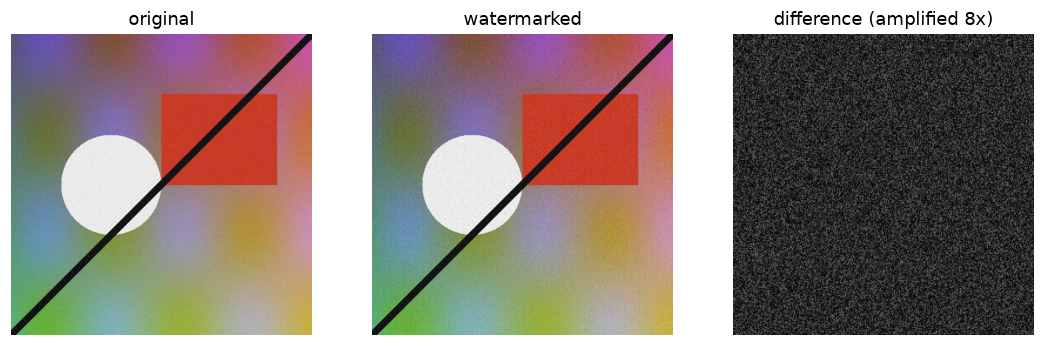

In [4]:
ENROLLMENT_ID = 123456789
Y_wm, certificates = embed.embed_luminance(Y, enrollment_id=ENROLLMENT_ID)
wm = im.replace_luminance(bgr, Y_wm)

print(f"PSNR (Y): {cv2.PSNR(Y, Y_wm):.2f} dB   | SHA-256 certificates per block: {len(certificates)}")
diff = np.abs(Y.astype(int) - Y_wm.astype(int))
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); ax[0].set_title("original")
ax[1].imshow(cv2.cvtColor(wm, cv2.COLOR_BGR2RGB)); ax[1].set_title("watermarked")
ax[2].imshow(diff * 8, cmap="gray", vmin=0, vmax=255); ax[2].set_title("difference (amplified 8x)")
for a in ax: a.axis("off")
plt.show()

## 4. Two layers with different jobs

| Layer | Location | Carries | Behaviour | Answers |
|---|---|---|---|---|
| Semi-fragile | HL | 256-bit fingerprint per block | sensitive to edits | which part changed? |
| Robust | LL | 32-bit ID + CRC-16, repeated 5x per block | survives compression | which enrolment did this image come from? |

The ID is extracted by soft *voting* across **all** blocks, then validated with the CRC. That is why the ID survives
compression that has already damaged the semi-fragile layer. Test it by lowering the JPEG quality:

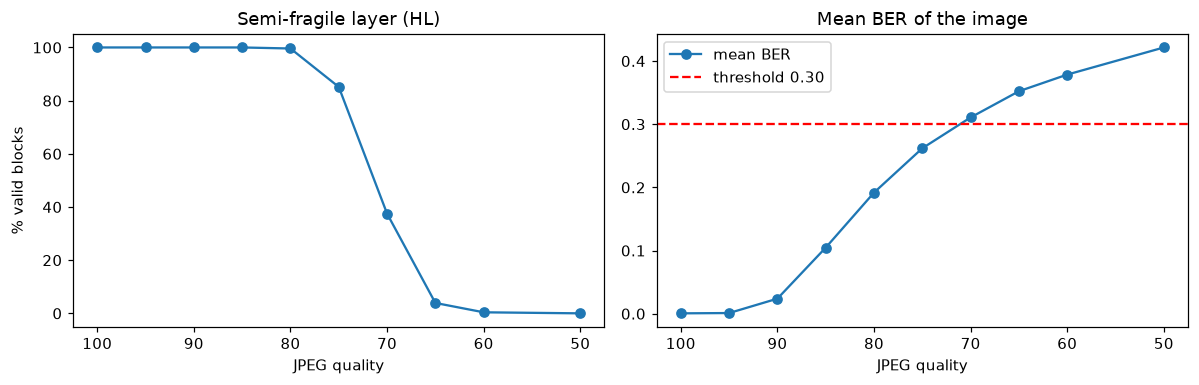

quality : [100, 95, 90, 85, 80, 75, 70, 65, 60, 50]
ID read : [True, True, True, True, True, True, True, True, True, True]


In [5]:
qualities = [100, 95, 90, 85, 80, 75, 70, 65, 60, 50]
valid, mean_ber, id_ok = [], [], []
for q in qualities:
    j = im.jpeg(wm, q)
    r = verify.verify_luminance(im.luminance(j))
    idv, k = robust_id.extract_id(im.luminance(j))
    valid.append(r["percent_valid"]); mean_ber.append(r["ber_map"].mean())
    id_ok.append(idv == ENROLLMENT_ID)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(qualities, valid, "o-"); ax[0].invert_xaxis()
ax[0].set_xlabel("JPEG quality"); ax[0].set_ylabel("% valid blocks"); ax[0].set_title("Semi-fragile layer (HL)")
ax[1].plot(qualities, mean_ber, "o-", label="mean BER")
ax[1].axhline(BER_THRESHOLD, color="r", ls="--", label="threshold 0.30")
ax[1].invert_xaxis(); ax[1].set_xlabel("JPEG quality"); ax[1].legend(); ax[1].set_title("Mean BER of the image")
plt.tight_layout(); plt.show()
print("quality :", qualities)
print("ID read :", id_ok)

With light to moderate compression almost every block is valid. As compression gets heavier, the mean BER rises
towards the threshold and many blocks are wrongly flagged as invalid, while the ID can still be read. That is why
the ID is a separate layer: after heavy compression it still points to the enrolment the image came from. This
behaviour depends on the image and the channel, so **the threshold must be calibrated per channel**.

## 5. Local manipulation and splicing

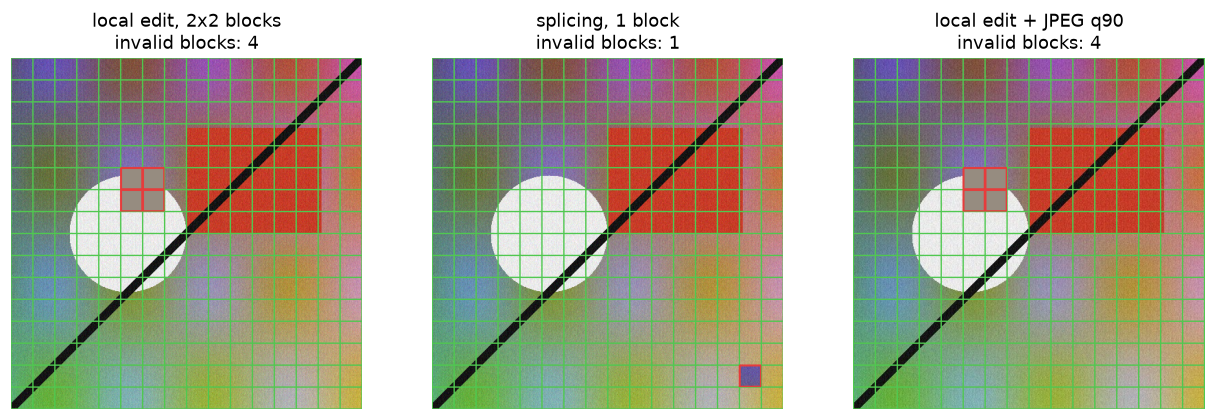

In [6]:
h, w = Y.shape[0] // 32, Y.shape[1] // 32
cases = {
    "local edit, 2x2 blocks": im.local_edit(wm, h // 3, w // 3),
    "splicing, 1 block": im.splice(wm, (1, 1), (h - 2, w - 2)),
    "local edit + JPEG q90": im.jpeg(im.local_edit(wm, h // 3, w // 3), 90),
}
fig, ax = plt.subplots(1, 3, figsize=(14, 4.8))
for a, (n, img) in zip(ax, cases.items()):
    r = verify.verify_luminance(im.luminance(img))
    a.imshow(cv2.cvtColor(im.overlay(img, r["valid_map"]), cv2.COLOR_BGR2RGB))
    a.set_title(f"{n}\ninvalid blocks: {(~r['valid_map']).sum()}"); a.axis("off")
plt.show()

### How small an edit is still detected?

Measure the BER of one edited block (a square area in the middle of the block, overwritten with a flat colour)
through the real pipeline.

In [7]:
by, bx = 5, 6
block_wm = Y_wm[by*32:(by+1)*32, bx*32:(bx+1)*32].copy()
print("edit size (pixels) | block BER | detected (BER > 0.30)")
for s in [1, 2, 4, 8, 12, 16, 24, 32]:
    b = block_wm.copy()
    o = (32 - s) // 2
    b[o:o+s, o:o+s] = 128
    ber_b = verify.verify_block(b, by, bx)
    print(f"{s:>2} x {s:<2}             | {ber_b:.3f}     | {ber_b > BER_THRESHOLD}")

edit size (pixels) | block BER | detected (BER > 0.30)
 1 x 1              | 0.000     | False
 2 x 2              | 0.000     | False
 4 x 4              | 0.008     | False
 8 x 8              | 0.031     | False
12 x 12             | 0.059     | False
16 x 16             | 0.113     | False
24 x 24             | 0.289     | False
32 x 32             | 0.492     | True


On this synthetic image, an edit inside one block is only detected once almost the whole block changes:
a 24x24 area (56% of the block) is still below the threshold, while 32x32 crosses it. This is the sensitivity
limit of the scheme: a threshold loose enough to tolerate compression means edits smaller than one block can
slip through. Real results depend on image content and the kind of edit; the edit in the demo below covers 2x2 full blocks.

Green = valid, red = detected as invalid. A local edit is localised exactly to the blocks that changed.
Splicing is detected because the moved block carries the fingerprint (position salt) of where it came from.

## 6. ML-DSA-44 signature: who vouches for it?

A watermark only proves integrity. The algorithm is public, so anyone can build an image with a watermark that
looks valid. To prove the **publisher**, the root hash of all certificates is signed with
**ML-DSA-44** (FIPS 204, designed to resist quantum computers). The private key is held only by the publisher;
anyone can check it with the public key.

In [8]:
pub, priv = signing.generate_keys()          # keys are generated fresh and never saved to disk
info = signing.sign_certificates(certificates, priv)
print("public key size :", len(pub), "bytes")
print("signature size  :", len(base64.b64decode(info["signature_b64"])),
      "bytes (too large to embed in the image -> stored on a server, referenced via the ID)")
print("original certificates :", signing.verify(certificates, info, pub))
forged = dict(certificates); forged["0_0"] = "0" * 64
print("altered certificates  :", signing.verify(forged, info, pub))
other_pub, _ = signing.generate_keys()
print("another public key    :", signing.verify(certificates, info, other_pub))

public key size : 1312 bytes
signature size  : 2420 bytes (too large to embed in the image -> stored on a server, referenced via the ID)
original certificates : {'valid': True, 'reason': 'Valid signature: the certificates are authentic and intact.'}
altered certificates  : {'valid': False, 'reason': 'Root hash mismatch: the certificates changed after signing.'}
another public key    : {'valid': False, 'reason': 'Invalid signature for this public key.'}


## 7. Try your own image

Set `PATH` to a PNG or JPEG file (colour or grayscale), then run the cell below. Use an image you are allowed to
use; do not upload personal documents to a public repository.

In [9]:
import os
PATH = None   # example: "my_photo.png"
if PATH:
    bgr2, Y2 = im.read_image(PATH)
    Yw2, _ = embed.embed_luminance(Y2, enrollment_id=ENROLLMENT_ID)
    wm2 = im.replace_luminance(bgr2, Yw2)
    os.makedirs("../outputs", exist_ok=True)
    cv2.imwrite("../outputs/own_image_watermarked.png", wm2)   # save as PNG (lossless)
    r = verify.verify_luminance(im.luminance(wm2))
    print(f"PSNR {cv2.PSNR(Y2[:Yw2.shape[0], :Yw2.shape[1]], Yw2):.2f} dB | valid blocks {r['percent_valid']:.1f}%")
else:
    print("PATH is not set yet.")

PATH is not set yet.


## Limitations

- **Resizing and geometric transforms** shift the block grid, so verification and ID extraction fail.
- **Heavy compression**: the semi-fragile layer can raise false alarms on intact images; the threshold must be calibrated per channel.
- **Flat blocks** (no texture) are more prone to false alarms.
- The JPEG simulation here is **not** a replica of WhatsApp compression.
- `dilithium-py` is a pure-Python implementation for research and teaching, not for production.